# Lab 1 Agent-Dev (build the pipeline yourself, with help)

This is the **developer stage** of a two-stage exercise: an **agent**<sub>4</sub> helps you *write* the pipeline's tools, one file at a time.

New to this developing and this vocabulary? See `agent_dev/GLOSSARY.md`. A small number like the one above points back to it.

## Before you start, a few terms

"Agent" gets used loosely, so let's be precise. (Full list:
`agent_dev/GLOSSARY.md`; a number like this<sub>1</sub> points back to
it.)

- **The LLM**<sub>1</sub> is just the model (Gemini or Groq): a
  **transformer**<sub>3</sub> that predicts the next **token**<sub>2</sub>
  from whatever text it's given. No memory between calls, no way to
  read a file or run code by itself.
- **A tool**<sub>5</sub> is what turns a plain chatbot into something
  that acts: a Python **function**<sub>37</sub> with a name, typed
  parameters, and a docstring, wrapped so the model can request it by
  name. The model never runs a tool itself. It only predicts "call
  this tool with these arguments," and the harness actually executes
  it.
- **The harness**<sub>6</sub> is what turns that into an agent. It
  resends the whole conversation every call, notices when the model
  asks to run a tool, runs it, and feeds the result back in. Here
  that's `graph_core.py` (a LangGraph **state machine**<sub>28</sub>),
  plus the chat widget, already built for you.
- **LangGraph**<sub>7</sub> is the library the harness is built with.
  Instead of hand-writing the send-call-run-repeat loop, you describe
  it as a graph: named steps (**"nodes"**<sub>8</sub>) connected by
  **edges**<sub>9</sub> that say what runs next. `graph_core.py` has
  three: `agent` (calls the model), `tool_node` (runs the tool),
  `discuss` (comments on the result). That's why "one tool call, then
  a comment, then stop" always holds, no matter what you or the model
  try.
- **Memory**<sub>10</sub> here just means the conversation list the
  harness resends every call, gone when the kernel restarts. A
  longer-lived system might use a database or a
  **vector store**<sub>11</sub> instead.

The only thing you're responsible for is what goes on inside a tool:
the function itself.

**`@tool`**, from `langchain_core.tools`, is the
**decorator**<sub>19</sub> every tool starts with. It builds a
`.args_schema` from the function's **type hints**<sub>21</sub> and
**docstring**<sub>22</sub>, and the model calls it correctly using only
that **schema**<sub>20</sub>; it never reads the function body. Skip
a type hint and the model has to guess that parameter's type; skip
docstring detail and it won't know when to call the tool.
`premade_tools/data_loading_tools.py`'s `load_dataset_tool` shows the
pattern.

**Why types matter here specifically:** a vague type makes the model
guess silently. Your code runs, just on the wrong input, no error.
An incompatible type can make the whole call fail outright: Gemini
rejects a fixed-length tuple like `Tuple[int, int]` this way.
`agent_dev/BACKEND_SCHEMA_NOTES.md` lists exactly which types are safe
on both backends. The agent is instructed to read that page itself
before typing any parameter, using its one tool that reaches outside
your workspace (`read_spec_file_tool`, allowed for exactly this page
and two others, nothing more). Worth reading yourself too, so you'd
recognize the problem if you ever saw it in a raw error message.

Four kinds of tools show up in this course: **read-only** (just
reports something, e.g. `inspect_data_tool`), **pipeline** (changes
session state, e.g. `build_dtm_tool`), **meta** (manages what the
agent can do, e.g. `propose_file_tool`), and **real-world** (acts
outside the machine, not used here, but the mechanism is the same).

You're building the eighteen tools that aren't `load_dataset_tool` or
`visualize_result_tool`.

## Your three reference files

Everything you need to build these tools correctly lives in
`agent_dev/`, in three short files. Read all three before you start:

- **`TOOLS_PIPELINE_BREAKDOWN.md`**: the exact shape every tool you
  build has to match, what it should return, what the shared `session`
  object holds, plus extra detail for the trickier tools. Read this
  before asking the agent to build anything.
- **`TEST_FIXTURE.md`**: a tiny, 8-document practice dataset with the
  correct answer for every tool, worked out by hand, not by running
  your own code. Use it to test what you build against real numbers,
  not guesses.
- **`BACKEND_SCHEMA_NOTES.md`**: one specific way of writing a
  parameter that breaks on Gemini (not Groq). Read this before you or
  the agent decide how to type a tool's parameters.

Why read them yourself, not just leave it to the agent: the agent can
only open these three when you point it at the right one by name, and
never on its own just because it seems relevant. Reading them yourself
means you can actually check what the agent tells you against the real
thing, instead of taking its word for it.

## How writing works

Two steps, two messages:
1. You ask for code. The agent proposes it and shows a
   **diff**<sub>26</sub> or preview. **Nothing is written yet.**
2. Only after you approve in your *next* message does it write the
   file. This is a **structural**<sub>29</sub> rule, not something you
   or the model can skip: propose and write can never happen in the
   same turn.

**The agent can't see a finished reference implementation**<sub>33</sub>.
Its file tools are confined to your own **workspace**<sub>25</sub>
(`agent_dev_workspace/`), which starts empty. See
`agent_dev/TOOLS_PIPELINE_BREAKDOWN.md` for the shape your code needs
to match.

Same loop as a diagram, one tool at a time:

```mermaid
flowchart TD
    A["You ask for one specific tool,\nor push back on a plan first"] --> B["Agent proposes the code\n(nothing written yet)"]
    B --> C{"You review it"}
    C -- "request changes" --> B
    C -- "approve" --> D["Agent writes the file"]
    D --> E["You ask for a test against\nthe fixture's known answers"]
    E --> F["Agent proposes the test\n(same review gate)"]
    F --> G{"You review, approve"}
    G -- "approve" --> H["Agent writes the test"]
    H --> I["You ask it to run the test"]
    I --> J["Agent actually runs it\n(real pass/fail, not a guess)"]
    J -- "fails" --> B
    J -- "passes" --> K["Move to the next tool"]
    K --> A
```

Every arrow back to "You" is a turn the graph forces to stop and wait
for your next message. No shortcuts: no "written" without your
approval, no "passes" without `run_tests_tool` actually running.

## Which tools you're actually building

`agent_dev/TOOLS_PIPELINE_BREAKDOWN.md` has the full table of all
eighteen tools and the exact **interface**<sub>23</sub> your code
needs to match: the `session` object, the `make_tools(session)`
**contract**<sub>24</sub>, all of it. Read it once before you start.

Two exceptions: `load_dataset_tool`
(`premade_tools/data_loading_tools.py`) and `visualize_result_tool`
(`premade_tools/visualization_tools.py`, which just renders a bar
chart of a stored result). `load_dataset_tool` is worth reading first,
since it's the pattern your own eighteen tools need to follow:

```python
@tool
def load_dataset_tool(
    categories: list[str] = None,
    file_path: str = None,
    text_column: str = None,
    label_column: str = None,
) -> dict:
    """Load a dataset. Two mutually exclusive modes, pass exactly one:
    `categories` for built-in 20-newsgroups, or `file_path` (plus
    `text_column`, `label_column`) for a local CSV.

    Args:
        categories: newsgroup names, e.g. ["alt.atheism", "soc.religion.christian", "comp.graphics", "sci.med"]. Mode 1 only.
        file_path: path to a local CSV, relative to the repo root. Mode 2 only.
        text_column: CSV column with the document text. Required with file_path.
        label_column: CSV column with the category/label. Required with file_path.
    """
    ...
```

The type hints, the two-modes docstring, the
`session.store_result(...)` call at the end: that's the shape to
copy. The only thing off-limits is a finished answer for the tools
*you're* building.

**How this one would have been built, if it weren't done for you
already:** the same propose-then-approve conversation you're about
to have.

> **You:** Let's build load_dataset_tool in tools_data.py. It needs to
> support two ways of loading data: the built-in 20-newsgroups subset
> by category, or a local CSV with a text column and a label column.
> Both should end up in the same shape afterward so nothing downstream
> has to care which one was used.
>
> **Agent:** Here's the plan: one function, two mutually exclusive
> modes selected by which arguments are passed: `categories` for
> 20-newsgroups, `file_path` plus `text_column`/`label_column` for a
> CSV. Both branches build a DataFrame with the same `text`,
> `category_name`, and `category` columns, so `session.dataframe` looks
> identical either way. Want me to propose it?
>
> **You:** Yes, propose it.
>
> **Agent:** *(proposes the code, explains the two branches, the
> normalization step, and the `session.store_result(...)` call)*
>
> **You:** Looks right. Write it.

Same propose, discuss, approve, write sequence as "How writing works"
above, just already run once, as your reference.

## What kind of help you get, tool by tool

Not every tool comes with the same amount of scaffolding. Twenty
total, three different levels:

- **2 provided, already built**: `load_dataset_tool` and
  `visualize_result_tool`. Nothing to build here; read them for
  reference.
- **16 with a full contract and a known answer**: everything else
  except the two listed below. `TOOLS_PIPELINE_BREAKDOWN.md` defines
  exactly what each should return, and `TEST_FIXTURE.md` has a
  worked-out correct answer to test against.
- **2 with neither, on purpose**: `inspect_data_tool` and
  `binarize_labels_tool`. No defined contract, no known answer in the
  fixture. You still build these with the agent's help, the same
  propose-approve-write process as any other tool, but you're the one
  who decides what they should return and what a reasonable test
  looks like, using what you've picked up from the other sixteen.
  They were picked for this specifically because nothing else in the
  pipeline depends on their exact shape, and because they're simple
  enough that you shouldn't get stuck: if you can build the other
  sixteen, you can reason through these two on your own.

If you ask the agent to test one of these last two the way you tested
the others (against a known-answer number), it should tell you plainly
that no known answer exists for that tool, not invent one. That's the
correct behavior, not a bug.

## Work from the spec, not from memory

Three spec files, all in `agent_dev/`: `TOOLS_PIPELINE_BREAKDOWN.md`
(the interface contract, the `session` object, the `make_tools(session)`
shape), `TEST_FIXTURE.md` (the fixture data and known answers), and
`BACKEND_SCHEMA_NOTES.md` (which parameter types are safe on both
backends). Read all three yourself before you start.

The agent has exactly one tool that reaches outside your own workspace:
`read_spec_file_tool`, and it can only read these same three files by
exact name, nothing else, no reference implementation anywhere in
reach. It's instructed to call it for the relevant spec before
proposing a tool's code, a test's expected numbers, or a parameter's
type, if it hasn't already this conversation. That's what makes this
**"spec-driven development"**<sub>34</sub> actually true, not just a
name: agree on a written spec, then have the agent go read the current
text of it and build against that, rather than recalling it from
whatever it was told when it was set up.

**You should still be the one who names the spec file, every time it
applies, not just trust that it will check on its own.** The agent is
instructed to call `read_spec_file_tool` before proposing code, a
test, or a parameter type, whether or not you name the file. But
instruction-following isn't guaranteed on every single turn, the same
way any rule in this agent's instructions could in principle be missed
once, and describing what you want in your own words gives it more
room to skip the fetch and answer from its general sense of the
assignment instead. Say "Build variance_filter_tool matching
TOOLS_PIPELINE_BREAKDOWN.md's contract," not "build me the variance
filter tool." Say "Test it against known answer 5 in TEST_FIXTURE.md,"
not the number itself. Naming the file is both a nudge that makes the
fetch more likely and something you can point back to if it doesn't
happen: a proposal that doesn't match what the named file actually
says is a clear sign it skipped the read. Skipping the read is exactly
the situation this whole setup exists to avoid, since a guessed
contract or number is a **hallucination**<sub>16</sub> waiting to
happen, not a shortcut that happens to still work; a plausible-sounding
contract or number that's actually wrong is worse than an honest "I'm
not sure," since it looks just as confident either way.

**Then actually make the agent go read it, don't just assume it
will.** If you're ever unsure whether it did, or a proposal looks like
it's guessing at a contract or a number rather than citing one, ask it
directly: "did you read TOOLS_PIPELINE_BREAKDOWN.md for this?" A
correctly-behaving agent should be able to say yes and point to what it
found there; if it can't, don't accept the proposal, ask it to actually
read the spec first.

## Why testing here means testing against a fixture

**A test**<sub>35</sub>: code that runs your function on a known
input and checks the output with **`assert`**<sub>39</sub>. It's a
real file, same as any tool file: propose it, approve it, and it's
written to disk.

**Why test at all:** a tool can run cleanly, return something
**JSON-serializable**<sub>32</sub>, and still give the wrong answer.
"Doesn't crash" and "is correct" aren't the same claim. A test catches
the second one, now, before it affects anything else.

**A fixture**<sub>36</sub>: a small, fixed input with a correct answer
worked out some other way, not by running your own code. The real
dataset is too big for this, and its "correct" answer usually isn't
known ahead of time. A fixture is small enough to check by hand, so a
test built on it has something real to compare against.

Two things worth knowing when the code *and* the test both come from
an agent:

Ask it to write both with no fixture in mind, and it invents its own
input and its own expected answer, straight from the code it just
wrote. That test can never fail: whatever the code computes becomes
"correct" by definition, even on a broken tool.

And an LLM can simply say a test passed without running it. It's
**stochastic**<sub>17</sub>, not **deterministic**<sub>18</sub> like a
real test, and it can state something false confidently, a
**hallucination**<sub>16</sub>, not a lie, just wrong. That's why
`run_tests_tool` actually launches **pytest**<sub>38</sub> as a real
**subprocess**<sub>30</sub> and checks its real
**exit code**<sub>31</sub>, instead of asking the agent whether it
thinks the test passed.

Read `agent_dev/TEST_FIXTURE.md` before your first test. It has the
real fixture data and exact numbers to test against, worked out
independently, never by asking the same agent that wrote a tool what
its own tool should return. Known answers exist for sixteen of the
eighteen tools you build (`visualize_result_tool` is provided, out of
scope); `inspect_data_tool` and `binarize_labels_tool` are the two
deliberate exceptions, covered in "What kind of help you get, tool by
tool" above.

## 0. Setup: your name, a backend, and its API key

Enter your name and student ID. Both get written into your session
log's header so grading can match your log to you.

Two **backends**<sub>12</sub>: `groq` or `gemini`. **Groq is the
recommended default**, faster on tool-calling turns (Gemini can take
up to a minute, sometimes fails outright). Use Gemini as a fallback
once Groq's **rate limit**<sub>13</sub> runs out. Set up `config/.env`
with your key first (see `config/.env.example`).

Got more than one key? **Turn on multi-provider
fallback**<sub>14</sub>: if your backend hits a rate limit
mid-session, it automatically retries with the next one instead of
leaving you stuck. Worth it: both providers' free tiers only reset
once a day (Groq at midnight UTC, Gemini at midnight Pacific).

Type `/status` in the chat at any point to see which of your keys
are still active and which have hit a rate limit this session,
handled entirely by the chat widget itself, not the agent, so it
never uses a turn or shows up in your graded log.

Run the cell below, fill it in, and click **Confirm**.

In [1]:
from agent_pipeline.backend_widget import select_backend

backend_choice = select_backend()

## 1. What to try

The chat launches below. Work through this in two phases.

Each numbered line below is tagged **[PROMPT]** or **[INSTRUCTION, not
a prompt]**. A `[PROMPT]` line is close to what you'd actually type.
An `[INSTRUCTION, not a prompt]` line tells you what to do or ask in
your own words; there's no fixed line to type there.

**Phase 1: try the test-and-run mechanism on something that already
works.** `load_dataset_tool` is already built and correct, so testing
it first shows you `run_tests_tool` without wondering whether a
failure is your fault or the test's.

1. **[PROMPT]** `What can you help me build?` (just conversation, no tool call)
2. **[PROMPT]** `Can you build a test for load_dataset_tool? It should load agent_dev/sample_fixture.csv and check that it produces exactly 8 documents, split 4 and 4 between catA and catB.`
3. **[PROMPT]** `That looks good, write it`
4. **[PROMPT]** `Does it pass? Run it.` (should pass immediately: you're confirming the mechanism, not debugging your own code)

Roughly:

> **You:** Can you build a test for load_dataset_tool? It should load
> agent_dev/sample_fixture.csv and check that it produces
> exactly 8 documents, split 4 and 4 between catA and catB.
>
> **Agent:** Here's a proposed `tests/test_load_dataset_tool.py`: it
> loads the fixture through `load_dataset_tool`, then asserts
> `n_documents == 8` and `counts_per_category == {"catA": 4, "catB": 4}`.
> Want me to write it?
>
> **You:** Yes, write it.
>
> **Agent:** Written. Ask me to run it whenever you're ready.
>
> **You:** Does it pass? Run it.
>
> **Agent:** Ran it with pytest: 1 passed. `load_dataset_tool` loaded
> exactly 8 documents, 4 catA and 4 catB, matching what the test
> expected.

Worth trying on purpose: asking for two things in one message doesn't
get you two things done.

> **You:** Write the test and run it, both right now.
>
> **Agent:** *(proposes the test, same as any first request, since
> nothing's approved yet)* Approve it and I'll write it, then ask me
> to run it separately. That's still two more turns.

Not caution: writing itself is already two turns (propose, approve)
before running can start.

> **You:** Does it pass? *(asked before anything's proposed)*
>
> **Agent:** There's no test written for `load_dataset_tool` yet. Want
> me to propose one first?

`run_tests_tool` only runs a file that actually exists; asking too
early just gets an honest "nothing to run yet."

**Phase 2: build one of your own eighteen, the same way, this time
actually using the spec.**

**One tool per message.** The agent runs at most one tool each time
you send a message. That's on purpose: it keeps you directing each
step, and it's what stops the agent from proposing and writing a file
in the same turn without your approval. So ask for one thing at a
time. If you ask for two anyway, it does the first and then tells you
the next step it wants ("Next it wants to run ..."); reply "go ahead"
to run it.

5. **[PROMPT]** `Before we build anything, read TOOLS_PIPELINE_BREAKDOWN.md and keep its tool table as the spec for everything we do from here.` Then, as its own separate message: **[PROMPT]** `Now read TEST_FIXTURE.md and keep its known answers as the spec for every test we write.` (two messages, not one, since reading each spec file is its own tool call; this anchors the agent on the real spec, not its general sense of the assignment)
6. **[PROMPT]** `Let's build build_dtm_tool in tools_dtm.py, matching TOOLS_PIPELINE_BREAKDOWN.md's contract. Before you propose any code, explain your plan and why.` (build_dtm_tool is a good first pick, since it only needs load_dataset_tool's output)
7. **[PROMPT]** `Why that approach and not some other way?`, if anything in the plan isn't obvious
8. **[PROMPT]** `Did you read TOOLS_PIPELINE_BREAKDOWN.md for that, or BACKEND_SCHEMA_NOTES.md for ngram_range's type?` (checks that it actually called read_spec_file_tool rather than recalling the contract from general sense; a correctly-behaving agent should be able to point to what it found)
9. **[PROMPT]** `That plan sounds good. Propose it, decorated with @tool and a type hint on every parameter.`
10. **[INSTRUCTION, not a prompt]** Review the diff, ask questions or request changes
11. **[PROMPT]** `That looks good, please write it`
12. **[PROMPT]** `Now build a test for build_dtm_tool using agent_dev/sample_fixture.csv, checking it against known answer 4 in TEST_FIXTURE.md.` (naming the known answer gets you exact numbers, not a typo waiting to happen)
13. **[PROMPT]** `That looks good, write it`
14. **[PROMPT]** `Does it pass? Run it.` (a real failure is possible now, and that's the test doing its job)
15. **[PROMPT]** `Show me what's in my workspace so far` (list_workspace_files_tool)
16. **[PROMPT]** `Read back tools_dtm.py` (read_workspace_file_tool)
17. **[INSTRUCTION, not a prompt]** Ask for the next tool, e.g. `Now let's build the variance filter in tools_filtering.py, matching TOOLS_PIPELINE_BREAKDOWN.md's contract`, and repeat

Two things the agent will *not* stop you from doing:
- `Just write the whole file, skip the explanation`: the agent will
  actually do this if you ask. Still a bad idea, since your log is
  what gets graded, and grading specifically checks for this.
- `Can you build me a load_dataset_tool?`: it'll propose one even
  though it already exists. Wasted effort, not a mistake it catches.

One thing that *is* still enforced: the agent never writes something
you didn't just approve. That's the propose/approve
**gate**<sub>27</sub> itself, not a rule about shortcuts.

**If the agent's reply is just "(No response came back for that...)"**,
that's not a bug, and not the session getting stuck. Behind the scenes,
an empty reply is automatically retried several more times,
switching to a different key or backend each time if you have more
than one configured, before this message ever shows, so seeing it at
all means every one of those attempts came back with nothing usable.
The tool call itself, if there was one that turn, already ran either
way; only the follow-up comment is missing. Just ask it to summarize,
or move to your next question.

In [2]:
from agent_dev.dev_session_state import DevSessionState
from agent_dev.graph import build_graph
from agent_pipeline.chat_widget import launch_chat

if "backend" not in backend_choice:
    raise RuntimeError("Pick a backend in the cell above and click Confirm before running this one.")
LLM_BACKEND = backend_choice["backend"]
MULTI_PROVIDER_MODE = backend_choice["multi_provider"]
STUDENT_NAME = backend_choice["student_name"]
STUDENT_ID = backend_choice["student_id"]

session = DevSessionState(workspace_dir="agent_dev_workspace")

if MULTI_PROVIDER_MODE:
    from agent_pipeline.llm_fallback import build_fallback_llm
    llm, active_chain = build_fallback_llm(LLM_BACKEND, temperature=0)
    print(f"Fallback chain (in order): {active_chain}")
else:
    from agent_pipeline.llm_backends import build_llm_for_backend
    llm = build_llm_for_backend(LLM_BACKEND, temperature=0)

app = build_graph(session, llm)

graph_state, logger = launch_chat(
    app, session, log_path="session_logs/agent_dev_session.jsonl.enc",
    student_name=STUDENT_NAME, student_id=STUDENT_ID, track="agent-dev",
    placeholder="Ask the agent to help you build a tool... (or type /status to see key rotation status)",
    llm=llm,
)

RuntimeError: Pick a backend in the cell above and click Confirm before running this one.

In [ ]:
from pathlib import Path
import importlib.util
import pandas as pd

# Load the tool module
path = Path("agent_dev_workspace/tools_dtm.py")
spec = importlib.util.spec_from_file_location("tools_dtm", path)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

# Find the assignment fixture
fixture = Path("agent_dev/sample_fixture.csv")
print("Fixture exists:", fixture.exists())

if fixture.exists():
    df = pd.read_csv(fixture)
    print("Columns:", df.columns.tolist())
    print("Shape:", df.shape)
    display(df.head())

In [ ]:

import pandas as pd
from agent_pipeline.session_state import SessionState
import importlib.util

# Load the implementation we created
spec = importlib.util.spec_from_file_location(
    "tools_dtm", "agent_dev_workspace/tools_dtm.py"
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

# Prepare the fixture in the same column format expected by the tools
session = SessionState()
session.dataframe = pd.read_csv(
    "agent_dev/sample_fixture.csv"
).rename(columns={"label": "category_name"})

# Build the DTM
tool = module.make_tools(session)[0]
result = tool.invoke({})

# Check against TEST_FIXTURE.md, known answer #4
assert result["n_documents"] == 8, result
assert result["n_terms"] == 5, result
assert result["feature_names"] == [
    "alpha", "always", "beta", "delta", "gamma"
], result
assert result["non_zero"] == 21, result
assert result["total_elements"] == 40, result
assert result["sparsity_pct"] == 47.5, result
assert session.feature_matrix.shape == (8, 5)
assert "count_vectorizer" in session.artifacts
assert result["result_id"] in session.results_store

print("PASS: build_dtm_tool matches known answer #4!")
print(result)


In [ ]:
import matplotlib
import seaborn
import numpy
import scipy

print("matplotlib:", matplotlib.__version__)
print("seaborn:", seaborn.__version__)
print("numpy:", numpy.__version__)
print("scipy:", scipy.__version__)

In [ ]:

from pathlib import Path

code = r'''
from typing import Any, Dict, List, Optional, Union

import matplotlib.pyplot as plt
import seaborn as sns
from langchain_core.tools import tool
from sklearn.feature_extraction.text import CountVectorizer


def make_tools(session: Any) -> list:
    """Create document-term matrix tools bound to a shared session."""

    @tool
    def build_dtm_tool(
        ngram_range: List[int] = [1, 1],
        max_features: Optional[int] = None,
        min_df: Union[int, float] = 1,
        max_df: Union[int, float] = 1.0,
    ) -> Dict[str, Any]:
        """Build a count-based document-term matrix.

        Args:
            ngram_range: Minimum and maximum n-gram sizes.
            max_features: Maximum vocabulary size, or None.
            min_df: Minimum document frequency for a term.
            max_df: Maximum document frequency for a term.
        """
        if session.dataframe is None:
            raise ValueError("No dataset is loaded.")
        if "text" not in session.dataframe.columns:
            raise ValueError("The dataframe must contain a 'text' column.")
        if (
            not isinstance(ngram_range, (list, tuple))
            or len(ngram_range) != 2
            or not all(isinstance(x, int) and not isinstance(x, bool)
                       for x in ngram_range)
            or ngram_range[0] < 1
            or ngram_range[0] > ngram_range[1]
        ):
            raise ValueError("ngram_range must contain two valid positive integers.")

        vectorizer = CountVectorizer(
            ngram_range=tuple(ngram_range),
            max_features=max_features,
            min_df=min_df,
            max_df=max_df,
        )
        texts = session.dataframe["text"].fillna("").astype(str)
        matrix = vectorizer.fit_transform(texts)
        feature_names = vectorizer.get_feature_names_out().tolist()

        session.feature_matrix = matrix
        session.feature_names = feature_names

        if "category_name" in session.dataframe.columns:
            session.set_labels(session.dataframe["category_name"].values)
        elif "category" in session.dataframe.columns:
            session.set_labels(session.dataframe["category"].values)

        session.artifacts["count_vectorizer"] = vectorizer

        n_documents, n_terms = matrix.shape
        total_elements = n_documents * n_terms
        non_zero = int(matrix.nnz)
        sparsity_pct = (
            100.0 * (1.0 - non_zero / total_elements)
            if total_elements else 0.0
        )

        result_id = session.next_result_id("dtm")
        summary = {
            "result_id": result_id,
            "n_documents": int(n_documents),
            "n_terms": int(n_terms),
            "non_zero": non_zero,
            "total_elements": int(total_elements),
            "sparsity_pct": round(sparsity_pct, 4),
            "feature_names": feature_names,
        }
        session.store_result(
            "build_dtm_tool",
            {
                "ngram_range": list(ngram_range),
                "max_features": max_features,
                "min_df": min_df,
                "max_df": max_df,
            },
            summary,
        )
        return summary

    @tool
    def dtm_heatmap_tool(
        n_terms: int = 20,
        n_documents: int = 20,
    ) -> Dict[str, Any]:
        """Create a heatmap for a subset of the document-term matrix.

        Args:
            n_terms: Maximum number of terms to display.
            n_documents: Maximum number of documents to display.
        """
        if session.feature_matrix is None or session.feature_names is None:
            raise ValueError("Build the document-term matrix first.")
        if not isinstance(n_terms, int) or isinstance(n_terms, bool) or n_terms < 1:
            raise ValueError("n_terms must be a positive integer.")
        if (
            not isinstance(n_documents, int)
            or isinstance(n_documents, bool)
            or n_documents < 1
        ):
            raise ValueError("n_documents must be a positive integer.")

        matrix = session.feature_matrix[:n_documents, :n_terms].toarray()
        terms = session.feature_names[:n_terms]
        doc_count, term_count = matrix.shape

        fig, ax = plt.subplots(figsize=(
            max(6, term_count * 0.8),
            max(3, doc_count * 0.45),
        ))
        sns.heatmap(
            matrix,
            annot=True,
            fmt="g",
            cmap="YlGnBu",
            xticklabels=terms,
            yticklabels=[f"Doc {i}" for i in range(doc_count)],
            ax=ax,
        )
        ax.set_title("Document-Term Matrix Heatmap")
        ax.set_xlabel("Terms")
        ax.set_ylabel("Documents")
        fig.tight_layout()
        session.pending_figure = fig

        result_id = session.next_result_id("dtm_heatmap")
        summary = {
            "result_id": result_id,
            "n_documents": int(doc_count),
            "n_terms": int(term_count),
            "feature_names": terms,
            "matrix": matrix.tolist(),
        }
        session.store_result(
            "dtm_heatmap_tool",
            {"n_terms": n_terms, "n_documents": n_documents},
            summary,
        )
        return summary

    return [build_dtm_tool, dtm_heatmap_tool]
'''

Path("agent_dev_workspace/tools_dtm.py").write_text(code)
print("Updated tools_dtm.py")


In [ ]:

import pandas as pd
import importlib.util
from agent_pipeline.session_state import SessionState

spec = importlib.util.spec_from_file_location(
    "tools_dtm", "agent_dev_workspace/tools_dtm.py"
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

session = SessionState()
session.dataframe = pd.read_csv(
    "agent_dev/sample_fixture.csv"
).rename(columns={"label": "category_name"})

tools = {t.name: t for t in module.make_tools(session)}

# Recheck build DTM
dtm = tools["build_dtm_tool"].invoke({})
assert dtm["n_documents"] == 8
assert dtm["n_terms"] == 5
assert dtm["non_zero"] == 21
assert dtm["feature_names"] == ["alpha", "always", "beta", "delta", "gamma"]

# Test default heatmap
heatmap = tools["dtm_heatmap_tool"].invoke({})
assert heatmap["matrix"] == session.feature_matrix.toarray().tolist()
assert heatmap["feature_names"] == ["alpha", "always", "beta", "delta", "gamma"]
assert heatmap["n_documents"] == 8
assert heatmap["n_terms"] == 5
assert session.pending_figure is not None
assert heatmap["result_id"] in session.results_store

# Test custom dimensions
small = tools["dtm_heatmap_tool"].invoke(
    {"n_terms": 2, "n_documents": 3}
)
assert small["matrix"] == [[3, 1], [2, 1], [1, 1]]

print("PASS: build_dtm_tool")
print("PASS: dtm_heatmap_tool default and custom dimensions")


In [ ]:

from pathlib import Path

code = r'''
from pathlib import Path
from typing import Any, Dict

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from langchain_core.tools import tool


def make_tools(session: Any) -> list:
    """Create dataset inspection and preprocessing tools."""

    @tool
    def tokenize_tool() -> Dict[str, Any]:
        """Tokenize each text document into lowercase word tokens.

        Returns token lists in document order and stores the result.
        """
        if session.dataframe is None or "text" not in session.dataframe.columns:
            raise ValueError("Load a dataset containing a 'text' column first.")

        import nltk
        from nltk.tokenize import word_tokenize

        try:
            nltk.data.find("tokenizers/punkt")
        except LookupError:
            nltk.download("punkt", quiet=True)
        try:
            nltk.data.find("tokenizers/punkt_tab")
        except LookupError:
            nltk.download("punkt_tab", quiet=True)

        tokens = [
            word_tokenize(str(text).lower()) if pd.notna(text) else []
            for text in session.dataframe["text"]
        ]
        session.artifacts["tokens"] = tokens

        rid = session.next_result_id("tokenize")
        summary = {
            "result_id": rid,
            "n_documents": len(tokens),
            "tokens": tokens,
        }
        session.store_result("tokenize_tool", {}, summary)
        return summary

    @tool
    def list_files_tool(subdirectory: str = ".") -> Dict[str, Any]:
        """List files and subdirectories under the project workspace.

        Args:
            subdirectory: Relative directory path to list.
        """
        root = Path.cwd().resolve()
        target = (root / subdirectory).resolve()
        if target != root and root not in target.parents:
            raise ValueError("Path must stay inside the project workspace.")
        if not target.is_dir():
            raise ValueError(f"Directory not found: {subdirectory}")

        files = sorted(p.name for p in target.iterdir() if p.is_file())
        directories = sorted(p.name for p in target.iterdir() if p.is_dir())

        rid = session.next_result_id("files")
        summary = {
            "result_id": rid,
            "subdirectory": subdirectory,
            "files": files,
            "directories": directories,
        }
        session.store_result(
            "list_files_tool", {"subdirectory": subdirectory}, summary
        )
        return summary

    @tool
    def inspect_data_tool() -> Dict[str, Any]:
        """Inspect the loaded dataset's dimensions, columns, types, and examples."""
        df = session.dataframe
        if df is None:
            raise ValueError("No dataset is loaded.")

        summary = {
            "result_id": session.next_result_id("inspect"),
            "n_rows": int(df.shape[0]),
            "n_columns": int(df.shape[1]),
            "columns": list(df.columns),
            "dtypes": {str(k): str(v) for k, v in df.dtypes.items()},
            "head": df.head(5).where(pd.notna(df.head(5)), None).to_dict("records"),
        }
        session.store_result("inspect_data_tool", {}, summary)
        return summary

    @tool
    def check_missing_tool() -> Dict[str, Any]:
        """Count missing values in each column and in the full dataset."""
        df = session.dataframe
        if df is None:
            raise ValueError("No dataset is loaded.")

        per_column = {str(k): int(v) for k, v in df.isna().sum().items()}
        summary = {
            "result_id": session.next_result_id("missing"),
            "missing_by_column": per_column,
            "total_missing": int(df.isna().sum().sum()),
            "rows_with_missing": int(df.isna().any(axis=1).sum()),
        }
        session.store_result("check_missing_tool", {}, summary)
        return summary

    @tool
    def check_duplicates_tool() -> Dict[str, Any]:
        """Count duplicate rows in the loaded dataset."""
        df = session.dataframe
        if df is None:
            raise ValueError("No dataset is loaded.")

        mask = df.duplicated()
        summary = {
            "result_id": session.next_result_id("duplicates"),
            "n_duplicates": int(mask.sum()),
            "duplicate_indices": [int(i) for i in df.index[mask].tolist()],
        }
        session.store_result("check_duplicates_tool", {}, summary)
        return summary

    @tool
    def sample_data_tool(n: int = 5, random_state: int = 42) -> Dict[str, Any]:
        """Return a reproducible random sample of dataset rows.

        Args:
            n: Number of rows to sample.
            random_state: Seed for reproducible sampling.
        """
        df = session.dataframe
        if df is None:
            raise ValueError("No dataset is loaded.")
        if not isinstance(n, int) or isinstance(n, bool) or n < 1:
            raise ValueError("n must be a positive integer.")
        if n > len(df):
            raise ValueError("n cannot exceed the number of dataset rows.")

        sampled = df.sample(n=n, random_state=random_state)
        records = sampled.astype(object).where(pd.notna(sampled), None).to_dict("records")
        summary = {
            "result_id": session.next_result_id("sample"),
            "n": n,
            "random_state": random_state,
            "indices": [int(i) for i in sampled.index.tolist()],
            "rows": records,
        }
        session.store_result(
            "sample_data_tool",
            {"n": n, "random_state": random_state},
            summary,
        )
        return summary

    @tool
    def describe_data_tool() -> Dict[str, Any]:
        """Summarize text character lengths and create a category boxplot."""
        df = session.dataframe
        if df is None or "text" not in df.columns:
            raise ValueError("Load a dataset containing a 'text' column first.")

        lengths = df["text"].fillna("").astype(str).str.len()
        desc = lengths.describe().to_dict()
        summary_stats = {
            str(k): round(float(v), 4) for k, v in desc.items()
        }
        summary = {
            "result_id": session.next_result_id("describe"),
            "character_length_summary": summary_stats,
            "character_lengths": [int(x) for x in lengths.tolist()],
        }

        if "category_name" in df.columns:
            categories = df["category_name"].fillna("Missing").astype(str)
            grouped = pd.DataFrame({
                "category_name": categories,
                "character_length": lengths,
            })
            per_category = {}
            for category, group in grouped.groupby("category_name", sort=True):
                stats = group["character_length"].describe().to_dict()
                per_category[str(category)] = {
                    str(k): round(float(v), 4) for k, v in stats.items()
                }
            summary["by_category"] = per_category

            fig, ax = plt.subplots(figsize=(7, 4))
            sns.boxplot(
                data=grouped,
                x="category_name",
                y="character_length",
                ax=ax,
            )
            ax.set_title("Text Length by Category")
            ax.set_xlabel("Category")
            ax.set_ylabel("Character Count")
            fig.tight_layout()
            session.pending_figure = fig

        session.store_result("describe_data_tool", {}, summary)
        return summary

    return [
        tokenize_tool,
        list_files_tool,
        inspect_data_tool,
        check_missing_tool,
        check_duplicates_tool,
        sample_data_tool,
        describe_data_tool,
    ]
'''

Path("agent_dev_workspace/tools_data.py").write_text(code)
print("Created tools_data.py")


In [ ]:
from pathlib import Path

path = Path("agent_dev_workspace/tools_dtm.py")
source = path.read_text(encoding="utf-8")

# Keep the current file unchanged if its structure is unexpected.
if "def build_dtm_tool(" not in source or "return [build_dtm_tool]" not in source:
    print("STOP: File structure differs from expected. No changes made.")
else:
    # Add the imports needed by the heatmap.
    source = source.replace(
        "from langchain_core.tools import tool",
        "import matplotlib.pyplot as plt\n"
        "import seaborn as sns\n"
        "from langchain_core.tools import tool",
        1,
    )

    new_tools = '''
    @tool
    def term_frequency_tool() -> Dict[str, Any]:
        """Calculate total term frequencies from the document-term matrix."""
        if session.feature_matrix is None or session.feature_names is None:
            raise ValueError("Build the document-term matrix first.")

        totals = session.feature_matrix.sum(axis=0).A1
        frequencies = [
            {"term": term, "frequency": int(freq)}
            for term, freq in zip(session.feature_names, totals)
        ]

        result_id = session.next_result_id("term_frequency")
        summary = {
            "result_id": result_id,
            "n_terms": len(frequencies),
            "term_frequencies": frequencies,
        }
        session.store_result("term_frequency_tool", {}, summary)
        return summary

    @tool
    def dtm_heatmap_tool(
        n_terms: int = 20,
        n_documents: int = 20,
    ) -> Dict[str, Any]:
        """Create a heatmap for a subset of the document-term matrix."""
        if session.feature_matrix is None or session.feature_names is None:
            raise ValueError("Build the document-term matrix first.")
        if not isinstance(n_terms, int) or isinstance(n_terms, bool) or n_terms < 1:
            raise ValueError("n_terms must be a positive integer.")
        if not isinstance(n_documents, int) or isinstance(n_documents, bool) or n_documents < 1:
            raise ValueError("n_documents must be a positive integer.")

        matrix = session.feature_matrix[:n_documents, :n_terms].toarray()
        terms = session.feature_names[:n_terms]
        doc_count, term_count = matrix.shape

        fig, ax = plt.subplots(figsize=(
            max(6, term_count * 0.8),
            max(3, doc_count * 0.45),
        ))
        sns.heatmap(
            matrix,
            annot=True,
            fmt="g",
            cmap="YlGnBu",
            xticklabels=terms,
            yticklabels=[f"Doc {i}" for i in range(doc_count)],
            ax=ax,
        )
        ax.set_title("Document-Term Matrix Heatmap")
        ax.set_xlabel("Terms")
        ax.set_ylabel("Documents")
        fig.tight_layout()
        session.pending_figure = fig

        result_id = session.next_result_id("dtm_heatmap")
        summary = {
            "result_id": result_id,
            "n_documents": int(doc_count),
            "n_terms": int(term_count),
            "feature_names": terms,
            "matrix": matrix.tolist(),
        }
        session.store_result(
            "dtm_heatmap_tool",
            {"n_terms": n_terms, "n_documents": n_documents},
            summary,
        )
        return summary

    return [build_dtm_tool, term_frequency_tool, dtm_heatmap_tool]
'''

    source = source.replace("    return [build_dtm_tool]", new_tools, 1)
    path.write_text(source, encoding="utf-8")
    print("Updated tools_dtm.py with all three tools.")

In [ ]:
import importlib
import tools_dtm

importlib.reload(tools_dtm)
tools = {t.name: t for t in tools_dtm.make_tools(session)}
print("Tools:", list(tools))

dtm = tools["build_dtm_tool"].invoke({})
print("DTM:", dtm["n_documents"], "documents,", dtm["n_terms"], "terms")

tf = tools["term_frequency_tool"].invoke({})
print("Frequencies:", {
    item["term"]: item["frequency"]
    for item in tf["term_frequencies"]
})

heatmap = tools["dtm_heatmap_tool"].invoke({})
print("Heatmap:", heatmap["n_documents"], "x", heatmap["n_terms"])

In [ ]:
import importlib
import tools_dtm

importlib.reload(tools_dtm)
tools = {t.name: t for t in tools_dtm.make_tools(session)}

print("Available tools:", list(tools))

dtm = tools["build_dtm_tool"].invoke({})
print("DTM:", dtm["n_documents"], "documents,", dtm["n_terms"], "terms")

tf = tools["term_frequency_tool"].invoke({})
print("Term frequencies:", {
    item["term"]: item["frequency"]
    for item in tf["term_frequencies"]
})

heatmap = tools["dtm_heatmap_tool"].invoke({})
print("Heatmap dimensions:", heatmap["n_documents"], "x", heatmap["n_terms"])

In [ ]:

import importlib.util
import pandas as pd
from agent_pipeline.session_state import SessionState

spec = importlib.util.spec_from_file_location(
    "tools_data", "agent_dev_workspace/tools_data.py"
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

session = SessionState()
session.dataframe = pd.read_csv(
    "agent_dev/sample_fixture.csv"
).rename(columns={"label": "category_name"})

tools = {t.name: t for t in module.make_tools(session)}

# 1. Tokenization
tok = tools["tokenize_tool"].invoke({})
assert tok["n_documents"] == 8
assert tok["tokens"][0] == ["always", "alpha", "alpha", "alpha", "beta"]
assert tok["tokens"][7] == []

# 2. File listing
files = tools["list_files_tool"].invoke({"subdirectory": "newdataset"})
assert files["directories"] == []
assert files["files"] == ["Reddit-stock-sentiment.csv"]

# 3. Dataset inspection
inspect = tools["inspect_data_tool"].invoke({})
assert inspect["n_rows"] == 8
assert inspect["n_columns"] == 2

# 4. Missing values
missing = tools["check_missing_tool"].invoke({})
assert missing["total_missing"] == 1

# 5. Duplicate rows
duplicates = tools["check_duplicates_tool"].invoke({})
assert duplicates["n_duplicates"] == 1

# 6. Reproducible sample
sample = tools["sample_data_tool"].invoke({"n": 4, "random_state": 42})
assert sample["indices"] == [1, 5, 0, 7]

# 7. Text length statistics and plot
describe = tools["describe_data_tool"].invoke({})
assert describe["character_lengths"] == [29, 23, 17, 30, 24, 18, 18, 0]
assert round(describe["character_length_summary"]["mean"], 3) == 19.875
assert session.pending_figure is not None

print("PASS: tokenize_tool")
print("PASS: list_files_tool")
print("PASS: inspect_data_tool")
print("PASS: check_missing_tool")
print("PASS: check_duplicates_tool")
print("PASS: sample_data_tool")
print("PASS: describe_data_tool")


In [ ]:
import os
print(os.listdir("agent_dev_workspace"))

In [ ]:
import os

print("Current directory:", os.getcwd())
print("Files here:", os.listdir())

In [ ]:
import sys
sys.path.insert(0, os.path.abspath("agent_dev_workspace"))

from tools_dtm import make_tools

In [ ]:
tools = make_tools(session)
print([t.name for t in tools])

In [ ]:
print(session.dataframe is None)

In [ ]:
dtm_tool = next(
    t for t in tools
    if t.name == "build_dtm_tool"
)

dtm_result = dtm_tool.invoke({})
print(dtm_result)

In [ ]:
from pathlib import Path

for name in ["agent_dev", "agent_dev_workspace"]:
    for file in Path(name).rglob("*.py"):
        if file.name == "tools_dtm.py":
            print(f"\n--- {file} ---")
            print(file.read_text())

In [ ]:
from pathlib import Path

p = Path(tools_dtm.__file__)
content = p.read_text()

print(content[-1500:])

In [ ]:
import importlib
import tools_dtm

importlib.reload(tools_dtm)

tools = tools_dtm.make_tools(session)
tool_map = {t.name: t for t in tools}

# Step 1: Build the document-term matrix first
dtm_result = tool_map["build_dtm_tool"].invoke({})
print("DTM built:", dtm_result["n_documents"], "documents")

# Step 2: Calculate term frequencies
result = tool_map["term_frequency_tool"].invoke({})
print(result)

In [ ]:
import numpy as np

# Recalculate term frequencies directly from the DTM
expected = np.asarray(session.feature_matrix.sum(axis=0)).ravel()
actual = tf_tool.invoke({})

print("Tool output:")
print(actual)

print("\nManual verification:")
print("Term names match:", actual["n_terms"] == len(session.feature_names))
print(
    "Frequencies match:",
    actual["term_frequencies"]
    == [
        {"term": str(term), "frequency": int(freq)}
        for term, freq in sorted(
            zip(session.feature_names, expected),
            key=lambda x: (-x[1], x[0])
        )
    ]
)

In [ ]:
import os

for root, dirs, files in os.walk("agent_dev_workspace"):
    dirs[:] = [d for d in dirs if d != "__pycache__" and d != ".ipynb_checkpoints"]
    for file in files:
        if file.endswith(".py"):
            print(os.path.join(root, file))

In [ ]:
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [
        d for d in dirs
        if d not in {".venv", ".git", "__pycache__", ".ipynb_checkpoints"}
    ]
    for file in files:
        if file.endswith((".md", ".txt")):
            print(os.path.join(root, file))

In [ ]:
!ls -la
!find . -path './.venv' -prune -o -path './.git' -prune -o -type f -name 'test_*.py' -print

In [ ]:

import importlib.util
import pandas as pd
from agent_pipeline.session_state import SessionState

spec = importlib.util.spec_from_file_location(
    "tools_dtm", "agent_dev_workspace/tools_dtm.py"
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

session = SessionState()
session.dataframe = pd.read_csv(
    "agent_dev/sample_fixture.csv"
).rename(columns={"label": "category_name"})

tools = {t.name: t for t in module.make_tools(session)}

# 1. Build document-term matrix
dtm = tools["build_dtm_tool"].invoke({})
assert dtm["n_documents"] == 8
assert dtm["n_terms"] == 5
assert dtm["non_zero"] == 21
assert dtm["total_elements"] == 40
assert dtm["sparsity_pct"] == 47.5
assert dtm["feature_names"] == [
    "alpha", "always", "beta", "delta", "gamma"
]

# 2. Term frequency
tf = tools["term_frequency_tool"].invoke({})
frequencies = {
    item["term"]: item["frequency"]
    for item in tf["term_frequencies"]
}
assert frequencies == {
    "alpha": 6,
    "always": 7,
    "beta": 3,
    "delta": 4,
    "gamma": 7,
}
assert tf["n_terms"] == 5

print("PASS: build_dtm_tool")
print("PASS: term_frequency_tool")


In [ ]:
import ast

with open("agent_dev_workspace/tools_dtm.py", "r") as f:
    source = f.read()

print("dtm_heatmap_tool" in source)

In [ ]:

# Re-import the updated module
import importlib.util
import pandas as pd
from agent_pipeline.session_state import SessionState

spec = importlib.util.spec_from_file_location(
    "tools_dtm", "agent_dev_workspace/tools_dtm.py"
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

session = SessionState()
session.dataframe = pd.read_csv(
    "agent_dev/sample_fixture.csv"
).rename(columns={"label": "category_name"})

tools = {t.name: t for t in module.make_tools(session)}

# Build the DTM first
tools["build_dtm_tool"].invoke({})

# Test default dimensions
heatmap = tools["dtm_heatmap_tool"].invoke({})

assert heatmap["n_documents"] == 8
assert heatmap["n_terms"] == 5
assert heatmap["feature_names"] == [
    "alpha", "always", "beta", "delta", "gamma"
]
assert heatmap["matrix"][:3][:] == [
    [3, 1, 1, 0, 0],
    [2, 1, 1, 0, 0],
    [1, 1, 1, 0, 0],
]
assert session.pending_figure is not None

print("PASS: dtm_heatmap_tool default dimensions")

# Test custom dimensions
custom = tools["dtm_heatmap_tool"].invoke({
    "n_terms": 2,
    "n_documents": 3,
})

assert custom["n_documents"] == 3
assert custom["n_terms"] == 2
assert custom["feature_names"] == ["alpha", "always"]
assert custom["matrix"] == [
    [3, 1],
    [2, 1],
    [1, 1],
]

print("PASS: dtm_heatmap_tool custom dimensions")


In [ ]:

import importlib.util
import pandas as pd
from agent_pipeline.session_state import SessionState

spec = importlib.util.spec_from_file_location(
    "tools_filtering",
    "agent_dev_workspace/tools_filtering.py",
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

session = SessionState()
session.dataframe = pd.read_csv(
    "agent_dev/sample_fixture.csv"
).rename(columns={"label": "category_name"})

# Build the DTM before filtering.
dtm_spec = importlib.util.spec_from_file_location(
    "tools_dtm",
    "agent_dev_workspace/tools_dtm.py",
)
dtm_module = importlib.util.module_from_spec(dtm_spec)
dtm_spec.loader.exec_module(dtm_module)

dtm_tools = {t.name: t for t in dtm_module.make_tools(session)}
dtm_tools["build_dtm_tool"].invoke({})

tools = {t.name: t for t in module.make_tools(session)}

# Test variance filtering.
variance = tools["variance_filter_tool"].invoke({"threshold": 0.15})

assert variance["n_kept"] == 4
assert set(variance["kept_features"]) == {
    "alpha", "beta", "delta", "gamma"
}
assert set(variance["removed_features"]) == {"always"}
assert abs(variance["variances"]["delta"] - 0.25) < 1e-8

print("PASS: variance_filter_tool")

# Test Pearson correlation.
pearson = tools["pearson_filter_tool"].invoke({
    "target_class": "catB"
})

assert abs(pearson["correlations"]["delta"] - 1.0) < 1e-8
assert abs(pearson["correlations"]["alpha"] - (-0.6882)) < 1e-3

print("PASS: pearson_filter_tool")

# Test Spearman correlation.
spearman = tools["spearman_filter_tool"].invoke({
    "target_class": "catB"
})

assert abs(spearman["correlations"]["delta"] - 1.0) < 1e-8
assert abs(spearman["correlations"]["alpha"] - (-0.75)) < 1e-3

print("PASS: spearman_filter_tool")


In [ ]:

print("Tools found:", list(tools.keys()))
print("Returned tools:", module.make_tools(session))


[PCA Algorithm](http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
[t-SNE Algorithm](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html)
[UMAP Algorithm](https://umap-learn.readthedocs.io/en/latest/basic_usage.html)

**Input:** Raw term-vector matrix

**Output:** Projections 

In [ ]:

from pathlib import Path

path = Path("agent_dev_workspace/tools_patterns.py")

print("File exists:", path.exists())
print("Actual path:", path.resolve() if path.exists() else "NOT FOUND")

if path.exists():
    print("\nFirst 25 lines:")
    print("\n".join(path.read_text().splitlines()[:25]))


In [ ]:
print(list(tools.keys()))

In [ ]:

import importlib.util
from pathlib import Path

path = Path("agent_dev_workspace/tools_patterns.py")
print("File:", path.resolve())

spec = importlib.util.spec_from_file_location(
    "my_patterns_module",
    str(path),
)
patterns_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(patterns_module)

print("Module loaded from:", patterns_module.__file__)
print("make_tools source:")
import inspect
print(inspect.getsource(patterns_module.make_tools)[:1200])

pattern_tools = patterns_module.make_tools(session)
print("Pattern tools:", [t.name for t in pattern_tools])


In [ ]:

import pandas as pd
from agent_pipeline.session_state import SessionState

session = SessionState()
session.dataframe = pd.read_csv(
    "agent_dev/sample_fixture.csv"
).rename(columns={"label": "category_name"})

pattern_tools = patterns_module.make_tools(session)
mine = {t.name: t for t in pattern_tools}["mine_patterns_tool"]

# Test 1: variance should keep zero terms on this fixture.
result = mine.invoke({
    "category_name": "catA",
    "filtering_method": "variance",
    "algorithm": "fpgrowth",
    "min_sup": 1,
})
print("Variance result:", result)
assert result["patterns"] == []
assert "no terms survived filtering" in result["note"]

# Test 2: term_frequency should keep zero terms too.
result = mine.invoke({
    "category_name": "catA",
    "filtering_method": "term_frequency",
    "algorithm": "fpgrowth",
    "min_sup": 1,
})
print("Term frequency result:", result)
assert result["patterns"] == []
assert "no terms survived filtering" in result["note"]

print("PASS: empty-result filtering cases")


In [ ]:

import importlib.util
import sys

spec = importlib.util.spec_from_file_location(
    "my_patterns_module",
    "agent_dev_workspace/tools_patterns.py"
)
patterns_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = patterns_module
spec.loader.exec_module(patterns_module)

pattern_tools = patterns_module.make_tools(session)
mine = {t.name: t for t in pattern_tools}["mine_patterns_tool"]

print("Loaded:", [t.name for t in pattern_tools])


In [ ]:

# Test 3: TF-IDF + FPGrowth
result = mine.invoke({
    "category_name": "catA",
    "filtering_method": "tfidf",
    "algorithm": "fpgrowth",
    "min_sup": 1,
})

print("TF-IDF + FPGrowth:", result)

assert result["vocabulary"], "Expected some terms to survive TF-IDF."
assert isinstance(result["patterns"], list)
assert result["n_patterns"] == len(result["patterns"])
assert (
    "patterns_catA_tfidf_fpgrowth" in session.artifacts
)

print("PASS: TF-IDF + FPGrowth")


In [ ]:

# Test 4: Top-K mining
topk_result = mine.invoke({
    "category_name": "catA",
    "filtering_method": "tfidf",
    "algorithm": "topk",
    "k": 5,
})
print("Top-K:", topk_result)

assert isinstance(topk_result["patterns"], list)
assert topk_result["n_patterns"] == len(topk_result["patterns"])
assert "patterns_catA_tfidf_topk" in session.artifacts

# Test 5: Maximal frequent patterns
max_result = mine.invoke({
    "category_name": "catA",
    "filtering_method": "tfidf",
    "algorithm": "maxfpgrowth",
    "min_sup": 1,
})
print("MaxFPGrowth:", max_result)

assert isinstance(max_result["patterns"], list)
assert max_result["n_patterns"] == len(max_result["patterns"])
assert "patterns_catA_tfidf_maxfpgrowth" in session.artifacts

print("PASS: Top-K and MaxFPGrowth")


In [ ]:

from PAMI.extras.convert import DF2DB
import inspect

print(inspect.signature(DF2DB.DF2DB))
print(inspect.getsource(DF2DB.DF2DB.__init__))


In [ ]:

from PAMI.frequentPattern.basic import FPGrowth
import inspect

print("FPGrowth constructor:", inspect.signature(FPGrowth.FPGrowth))
print("\nAvailable methods:")
print([
    name for name in dir(FPGrowth.FPGrowth)
    if not name.startswith("_")
])


In [ ]:

import importlib.util

spec = importlib.util.spec_from_file_location(
    "my_patterns_module",
    "agent_dev_workspace/tools_patterns.py"
)
patterns_module = importlib.util.module_from_spec(spec)
import sys
sys.modules[spec.name] = patterns_module
spec.loader.exec_module(patterns_module)

pattern_tools = patterns_module.make_tools(session)
mine = {t.name: t for t in pattern_tools}["mine_patterns_tool"]

print("Loaded:", [t.name for t in pattern_tools])


In [ ]:

import inspect
from PAMI.extras.convert import DF2DB

print(inspect.signature(DF2DB.DF2DB.convert2TransactionalDatabase))
print(inspect.getsource(DF2DB.DF2DB.convert2TransactionalDatabase))


In [ ]:

import importlib.util
import sys

spec = importlib.util.spec_from_file_location(
    "my_patterns_module",
    "agent_dev_workspace/tools_patterns.py"
)
patterns_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = patterns_module
spec.loader.exec_module(patterns_module)

pattern_tools = patterns_module.make_tools(session)
mine = {t.name: t for t in pattern_tools}["mine_patterns_tool"]

print("Loaded:", [t.name for t in pattern_tools])


In [ ]:

from pathlib import Path

code = '''from typing import Any, Dict, List, Optional, Union

from langchain_core.tools import tool
from sklearn.feature_extraction.text import CountVectorizer


def make_tools(session: Any) -> list:
    """Create document-term matrix tools bound to a shared session."""

    @tool
    def build_dtm_tool(
        ngram_range: List[int] = [1, 1],
        max_features: Optional[int] = None,
        min_df: Union[int, float] = 1,
        max_df: Union[int, float] = 1.0,
    ) -> Dict[str, Any]:
        """Build a document-term matrix from the text column in the session."""

        if session.dataframe is None:
            raise ValueError("No dataset is loaded. Load a dataset first.")

        if "text" not in session.dataframe.columns:
            raise ValueError("The dataframe must contain a 'text' column.")

        if (
            not isinstance(ngram_range, (list, tuple))
            or len(ngram_range) != 2
            or not all(isinstance(x, int) and not isinstance(x, bool)
                       for x in ngram_range)
            or ngram_range[0] < 1
            or ngram_range[0] > ngram_range[1]
        ):
            raise ValueError("ngram_range must contain two valid positive integers.")

        vectorizer = CountVectorizer(
            ngram_range=tuple(ngram_range),
            max_features=max_features,
            min_df=min_df,
            max_df=max_df,
        )

        texts = session.dataframe["text"].fillna("").astype(str)
        matrix = vectorizer.fit_transform(texts)
        feature_names = vectorizer.get_feature_names_out().tolist()

        session.feature_matrix = matrix
        session.feature_names = feature_names

        if "category_name" in session.dataframe.columns:
            session.set_labels(session.dataframe["category_name"].values)
        elif "category" in session.dataframe.columns:
            session.set_labels(session.dataframe["category"].values)

        session.artifacts["count_vectorizer"] = vectorizer

        n_documents, n_terms = matrix.shape
        total_elements = n_documents * n_terms
        non_zero = int(matrix.nnz)
        sparsity_pct = (
            100.0 * (1.0 - non_zero / total_elements)
            if total_elements else 0.0
        )

        result_id = session.next_result_id("dtm")
        summary = {
            "result_id": result_id,
            "n_documents": int(n_documents),
            "n_terms": int(n_terms),
            "non_zero": non_zero,
            "total_elements": int(total_elements),
            "sparsity_pct": round(sparsity_pct, 4),
            "feature_names": feature_names,
        }

        session.store_result(
            "build_dtm_tool",
            {
                "ngram_range": list(ngram_range),
                "max_features": max_features,
                "min_df": min_df,
                "max_df": max_df,
            },
            summary,
        )
        return summary

    return [build_dtm_tool]
'''

workspace = Path("agent_dev_workspace")
workspace.mkdir(exist_ok=True)
target = workspace / "tools_dtm.py"
target.write_text(code, encoding="utf-8")

print("Created:", target.resolve())


In [ ]:

from pathlib import Path

code = '''from typing import Any, Dict, List, Optional, Union

from langchain_core.tools import tool
from sklearn.feature_extraction.text import CountVectorizer


def make_tools(session: Any) -> list:
    """Create document-term matrix tools bound to a shared session."""

    @tool
    def build_dtm_tool(
        ngram_range: List[int] = [1, 1],
        max_features: Optional[int] = None,
        min_df: Union[int, float] = 1,
        max_df: Union[int, float] = 1.0,
    ) -> Dict[str, Any]:
        """Build a document-term matrix from the text column in the session."""

        if session.dataframe is None:
            raise ValueError("No dataset is loaded. Load a dataset first.")

        if "text" not in session.dataframe.columns:
            raise ValueError("The dataframe must contain a 'text' column.")

        if (
            not isinstance(ngram_range, (list, tuple))
            or len(ngram_range) != 2
            or not all(isinstance(x, int) and not isinstance(x, bool)
                       for x in ngram_range)
            or ngram_range[0] < 1
            or ngram_range[0] > ngram_range[1]
        ):
            raise ValueError("ngram_range must contain two valid positive integers.")

        vectorizer = CountVectorizer(
            ngram_range=tuple(ngram_range),
            max_features=max_features,
            min_df=min_df,
            max_df=max_df,
        )

        texts = session.dataframe["text"].fillna("").astype(str)
        matrix = vectorizer.fit_transform(texts)
        feature_names = vectorizer.get_feature_names_out().tolist()

        session.feature_matrix = matrix
        session.feature_names = feature_names

        if "category_name" in session.dataframe.columns:
            session.set_labels(session.dataframe["category_name"].values)
        elif "category" in session.dataframe.columns:
            session.set_labels(session.dataframe["category"].values)

        session.artifacts["count_vectorizer"] = vectorizer

        n_documents, n_terms = matrix.shape
        total_elements = n_documents * n_terms
        non_zero = int(matrix.nnz)
        sparsity_pct = (
            100.0 * (1.0 - non_zero / total_elements)
            if total_elements else 0.0
        )

        result_id = session.next_result_id("dtm")
        summary = {
            "result_id": result_id,
            "n_documents": int(n_documents),
            "n_terms": int(n_terms),
            "non_zero": non_zero,
            "total_elements": int(total_elements),
            "sparsity_pct": round(sparsity_pct, 4),
            "feature_names": feature_names,
        }

        session.store_result(
            "build_dtm_tool",
            {
                "ngram_range": list(ngram_range),
                "max_features": max_features,
                "min_df": min_df,
                "max_df": max_df,
            },
            summary,
        )
        return summary

    return [build_dtm_tool]
'''

workspace = Path("agent_dev_workspace")
workspace.mkdir(exist_ok=True)
target = workspace / "tools_dtm.py"
target.write_text(code, encoding="utf-8")

print("Created:", target.resolve())


In [ ]:
from pathlib import Path

path = Path("agent_dev_workspace/tools_reduction.py")
print("Exists:", path.exists())

if path.exists():
    print(path.read_text())

In [ ]:
import importlib.util
import sys

spec = importlib.util.spec_from_file_location(
    "my_reduction_module",
    "agent_dev_workspace/tools_reduction.py"
)
reduction_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = reduction_module
spec.loader.exec_module(reduction_module)

reduction_tools = reduction_module.make_tools(session)

print([t.name for t in reduction_tools])

In [ ]:
print("Feature matrix:", session.feature_matrix is not None)
print("Dataframe:", session.dataframe is not None)
print("Artifacts:", session.artifacts.keys())

In [ ]:
dtm_tools = {
    t.name: t
    for t in dtm_module.make_tools(session)
}

In [ ]:
dtm_tools = {
    t.name: t
    for t in dtm_module.make_tools(session)
}

print("Tools:", list(dtm_tools.keys()))
print("Session before:", session.feature_matrix is not None)

dtm_result = dtm_tools["build_dtm_tool"].invoke({})

print("DTM result:", dtm_result)
print("Session after:", session.feature_matrix is not None)

In [ ]:
import numpy as np
from scipy.spatial.distance import cdist, pdist

tsne_result = reduction_tools[0].invoke(
    {"method": "tsne", "perplexity": 2, "random_state": 42}
)
c = np.array(tsne_result["coordinates"])

# 1. bentuk dan nilai valid
assert c.shape == (8, 2) and np.isfinite(c).all()

# 2. reproducible dengan seed yang sama
c2 = np.array(reduction_tools[0].invoke(
    {"method": "tsne", "perplexity": 2, "random_state": 42})["coordinates"])
assert np.allclose(c, c2, atol=1e-5)

# 3. dokumen duplikat (5 dan 6) harus jatuh di titik yang sama
assert np.allclose(c[5], c[6], atol=1e-3)

# 4. struktur: jarak dalam-grup < jarak antar-grup (catA: 0-2, catB: 3-6)
A, B = c[:3], c[3:7]
within = (pdist(A).mean() + pdist(B).mean()) / 2
between = cdist(A, B).mean()
assert within < between

assert session.pending_figure is not None
print("PASS: t-SNE properties (known answer #8 is not reproducible across versions)")

In [ ]:
result = reduction_tools[0].invoke({"method": "pca"})

print("Method:", result["method"])
print("Documents:", len(result["coordinates"]))
print("Explained variance:", result["explained_variance_ratio"])
print("Plot created:", session.pending_figure is not None)
print("Result ID:", result["result_id"])

In [ ]:
for method in ["tsne", "umap"]:
    print(f"\nTesting {method.upper()}...")

    try:
        result = reduction_tools[0].invoke({"method": method})

        print("PASS")
        print("Documents:", len(result["coordinates"]))
        print("Plot created:", session.pending_figure is not None)

    except Exception as e:
        print("ERROR:", type(e).__name__, e)

In [ ]:
from pathlib import Path

fixture = Path("agent_dev/TEST_FIXTURE.md")
print(fixture.read_text())

In [ ]:
import importlib
import tools_reduction

importlib.reload(tools_reduction)

reduction_tools = tools_reduction.make_tools(session)

print("Before:", session.pending_figure)

pca_result = reduction_tools[0].invoke({"method": "pca"})

print("Coordinates:", pca_result["coordinates"][:2])
print("Variance:", pca_result["explained_variance_ratio"])
print("After:", session.pending_figure)
print("Figure created:", session.pending_figure is not None)

In [ ]:
import sklearn
import numpy as np

print("scikit-learn version:", sklearn.__version__)

tsne_result = reduction_tools[0].invoke({
    "method": "tsne",
    "perplexity": 2,
    "random_state": 42,
})

print("\nActual t-SNE coordinates:")
print(np.round(np.array(tsne_result["coordinates"]), 4))

print("\nExpected t-SNE coordinates:")
print(np.array(expected_tsne))

In [ ]:
import json
from pathlib import Path

nb = json.loads(
    Path("DM2026-Lab1-AgentDev.ipynb").read_text(encoding="utf-8")
)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if "TSNE(" in source or "learning_rate" in source:
        print(f"\n--- Cell {i + 1} ---")
        print(source[:2500])

In [ ]:
umap_result = reduction_tools[0].invoke({
    "method": "umap",
    "n_neighbors": 3,
    "random_state": 42,
})

print("UMAP coordinates:")
print(np.round(np.array(umap_result["coordinates"]), 4))

assert np.allclose(
    umap_result["coordinates"],
    expected_umap,
    atol=0.1
), "UMAP coordinates do not match known answer #9"

assert session.pending_figure is not None

print("PASS: Known answer #9 — UMAP")

In [ ]:
import inspect

print("Tool object:", reduction_tools[0])
print("Tool name:", reduction_tools[0].name)
print("Tool function source:")
print(inspect.getsource(reduction_tools[0].func))

In [ ]:
import inspect

print("Tool name:", reduction_tools[0].name)
print("Tool function source:")
print(inspect.getsource(reduction_tools[0].func))

In [ ]:

import importlib
import tools_reduction

# Reload the edited Python module
importlib.reload(tools_reduction)

# Recreate the tools using the current session
reduction_tools = tools_reduction.make_tools(session)

print("Reloaded:", tools_reduction.__file__)
print("Tools recreated:", [t.name for t in reduction_tools])


In [ ]:

direct = TSNE(
    n_components=2,
    random_state=42,
    perplexity=2,
).fit_transform(session.feature_matrix.toarray())

wrapped_result = reduction_tools[0].invoke({
    "method": "tsne",
    "perplexity": 2,
    "random_state": 42,
})

wrapped = np.array(wrapped_result["coordinates"])

print("Same coordinates:", np.allclose(direct, wrapped, atol=1e-5))
print("Direct first row:", direct[0])
print("Wrapped first row:", wrapped[0])


In [ ]:
import inspect
import tools_reduction

print(inspect.getsource(tools_reduction.make_tools))

In [ ]:
coords = np.array(tsne_result["coordinates"])

assert coords.shape == (8, 2)
assert np.isfinite(coords).all()

tsne_result_2 = reduction_tools[0].invoke({
    "method": "tsne",
    "perplexity": 2,
    "random_state": 42,
})

assert np.allclose(
    coords,
    np.array(tsne_result_2["coordinates"]),
    atol=1e-5,
)

print("PASS: t-SNE shape, finite values, and reproducibility")

In [ ]:
print(tsne_result["coordinates"])
print("Shape:", np.array(tsne_result["coordinates"]).shape)

In [ ]:
import numpy as np

# Known answer #7: PCA
expected_pca = np.array([
    [ 2.3669,  0.8871],
    [ 1.7039,  0.2642],
    [ 1.0408, -0.3587],
    [-2.0759,  1.0129],
    [-1.4554,  0.3405],
    [-0.8349, -0.3319],
    [-0.8349, -0.3319],
    [ 0.0894, -1.4822],
])

pca_result = reduction_tools[0].invoke({
    "method": "pca"
})

assert np.allclose(
    pca_result["coordinates"], expected_pca, atol=0.001
), "PCA coordinates do not match known answer #7"

assert np.allclose(
    pca_result["explained_variance_ratio"],
    [0.7532, 0.1965],
    atol=0.001
), "PCA explained variance does not match"

assert session.pending_figure is not None
print("PASS: Known answer #7 — PCA")


# Known answer #8: t-SNE
expected_tsne = np.array([
    [ 1330.9991,    32.1039],
    [  951.2459,   393.5588],
    [  530.8209,   682.9791],
    [-1558.6448,  -314.1625],
    [ -915.5153,  -346.3907],
    [ -280.0313, -1261.2115],
    [ -280.0313, -1261.2115],
    [ -701.3674,  1465.3973],
])

tsne_result = reduction_tools[0].invoke({
    "method": "tsne",
    "perplexity": 2,
    "random_state": 42,
})

assert np.allclose(
    tsne_result["coordinates"], expected_tsne, atol=1.0
), "t-SNE coordinates do not match known answer #8"

assert session.pending_figure is not None
print("PASS: Known answer #8 — t-SNE")


# Known answer #9: UMAP
expected_umap = np.array([
    [ 6.6811, -6.8218],
    [ 6.9907, -7.2245],
    [ 7.7022, -7.3712],
    [10.2228, -6.2310],
    [ 9.8759, -5.6537],
    [ 9.3831, -6.5748],
    [ 9.2153, -5.8297],
    [ 8.5860, -7.2622],
])

umap_result = reduction_tools[0].invoke({
    "method": "umap",
    "n_neighbors": 3,
    "random_state": 42,
})

assert np.allclose(
    umap_result["coordinates"], expected_umap, atol=0.1
), "UMAP coordinates do not match known answer #9"

assert session.pending_figure is not None
print("PASS: Known answer #9 — UMAP")

print("\nAll dimensionality reduction tests passed!")

In [ ]:
import sklearn
import inspect
from sklearn.manifold import TSNE

print("scikit-learn version:", sklearn.__version__)
print("TSNE defaults:", inspect.signature(TSNE))
print("Actual coordinates:")
print(np.array(tsne_result["coordinates"]).round(4))
print("Expected coordinates:")
print(expected_tsne)

In [ ]:
import itertools
import numpy as np
from sklearn.manifold import TSNE

print("expected_tsne:", type(expected_tsne), np.shape(expected_tsne))
print("X shape:", X.shape)

best = []
errors = {}

for init, lr, ee, mi, method in itertools.product(
    ["pca", "random"],
    ["auto", 10, 50, 100, 200, 500, 1000],
    [4, 12, 24],
    [250, 1000, 2000],
    ["barnes_hut", "exact"],
):
    try:
        c = TSNE(n_components=2, perplexity=2, random_state=42,
                 init=init, learning_rate=lr, early_exaggeration=ee,
                 max_iter=mi, method=method).fit_transform(X)
        best.append((np.max(np.abs(c - np.array(expected_tsne))),
                     init, lr, ee, mi, method))
    except Exception as e:
        errors[str(e)[:150]] = errors.get(str(e)[:150], 0) + 1

print("Berhasil:", len(best), "| Error:", sum(errors.values()))
for msg, n in errors.items():
    print(n, "x", msg)

best.sort(key=lambda t: t[0])
for b in best[:5]:
    print(b)

In [ ]:
from sklearn.manifold import TSNE
import sklearn
import numpy as np

X = session.feature_matrix.toarray()

print("sklearn version:", sklearn.__version__)
print("Matrix shape:", X.shape)
print("Matrix:\n", X)

configs = [
    {"init": "random", "learning_rate": 1000},
    {"init": "pca", "learning_rate": 1000},
    {"init": "random", "learning_rate": 200, "method": "exact"},
    {"init": "pca", "learning_rate": 200, "method": "exact"},
]

for config in configs:
    coords = TSNE(
        n_components=2,
        perplexity=2,
        random_state=42,
        **config,
    ).fit_transform(X)

    print("\nConfig:", config)
    print("First 3 coordinates:\n", np.round(coords[:3], 4))
    print(
        "Maximum absolute difference:",
        round(np.max(np.abs(coords - expected_tsne)), 4),
    )

In [ ]:
import json
from pathlib import Path

path = Path("DM2026-Lab1-AgentDev.ipynb")
nb = json.loads(path.read_text())

for i, cell in enumerate(nb["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    outputs = cell.get("outputs", [])

    if "Known answer" in source or "assert " in source:
        status = "PASS" if any(
            "PASS:" in str(out.get("text", []))
            for out in outputs
        ) else "Perlu dicek"

        errors = [
            out.get("ename", "") + ": " + out.get("evalue", "")
            for out in outputs
            if out.get("output_type") == "error"
        ]

        print(f"Cell {i}: {status}")
        for error in errors:
            print("  ", error)

In [ ]:
import numpy as np

umap_result = reduction_tools[0].invoke({
    "method": "umap",
    "n_neighbors": 3,
    "random_state": 42,
})

expected_umap = np.array([
    [6.6811, -6.8218],
    [6.9907, -7.2245],
    [7.7022, -7.3712],
    [10.2228, -6.2310],
    [9.8759, -5.6537],
    [9.3831, -6.5748],
    [9.2153, -5.8297],
    [8.5860, -7.2622],
])

actual_umap = np.array(umap_result["coordinates"])

print("Actual shape:", actual_umap.shape)
print("Actual coordinates:\n", np.round(actual_umap, 4))
print(
    "PASS:",
    actual_umap.shape == expected_umap.shape
    and np.allclose(actual_umap, expected_umap, atol=0.1),
)

In [ ]:
import importlib.util
import sys

spec = importlib.util.spec_from_file_location(
    "my_reduction_module",
    "agent_dev_workspace/tools_reduction.py",
)
reduction_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = reduction_module
spec.loader.exec_module(reduction_module)

reduction_tools = reduction_module.make_tools(session)

print([t.name for t in reduction_tools])

binarize_tool = next(
    t for t in reduction_tools
    if t.name == "binarize_labels_tool"
)

result = binarize_tool.invoke({})
print(result)

In [ ]:
from pathlib import Path

folder = Path("agent_dev_workspace")

for path in sorted(folder.glob("tools*.py")):
    print(path.name)

In [ ]:
import importlib.util
import sys

spec = importlib.util.spec_from_file_location(
    "my_exploration_module",
    "agent_dev_workspace/tools_exploration.py",
)
exploration_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = exploration_module
spec.loader.exec_module(exploration_module)

exploration_tools = exploration_module.make_tools(session)
exploration_by_name = {t.name: t for t in exploration_tools}

print(list(exploration_by_name))

In [ ]:
cosine_tool = exploration_by_name["cosine_similarity_tool"]

for doc1, doc2, expected in [
    (0, 1, 0.9847),
    (0, 3, 0.0909),
    (3, 4, 0.9847),
    (0, 7, 0.0),
]:
    result = cosine_tool.invoke({"doc1": doc1, "doc2": doc2})
    actual = result["similarity"]

    print(
        f"Docs {doc1}, {doc2}: {actual:.4f} | "
        f"Expected {expected:.4f} | "
        f"{'PASS' if abs(actual - expected) < 0.001 else 'CHECK'}"
    )

In [ ]:
import inspect
from pathlib import Path

p = Path("agent_dev_workspace/tools_reduction.py")
print(inspect.getsource(p.read_text if False else lambda: None) if False else "")
print(p.read_text())

In [ ]:
corr_tool = exploration_by_name["feature_correlation_matrix_tool"]
corr_result = corr_tool.invoke({})

print("Result ID:", corr_result.get("result_id"))
print("Feature order:", corr_result.get("features"))
print("Matrix shape:", len(corr_result.get("correlation_matrix", [])))
print("Heatmap created:", session.pending_figure is not None)

for row in corr_result.get("correlation_matrix", []):
    print([round(value, 4) for value in row])

In [ ]:
import inspect
import sklearn
from sklearn.manifold import TSNE

print("scikit-learn:", sklearn.__version__)
print(inspect.getsource(TSNE.__init__))

In [ ]:
from pathlib import Path

lines = Path("agent_dev/TEST_FIXTURE.md").read_text().splitlines()

for i in range(127, 162):
    print(f"{i + 1}: {lines[i]}")

In [ ]:
reduction_tools = reduction_module.make_tools(session)
reduction_by_name = {t.name: t for t in reduction_tools}

print(list(reduction_by_name))

In [ ]:
import itertools, numpy as np
from sklearn.manifold import TSNE
# X = DTM 8x5 dari fixture (dense)

for init, lr in itertools.product(["pca", "random"], [200, "auto"]):
    t = TSNE(n_components=2, perplexity=2, random_state=42,
             init=init, learning_rate=lr)
    Y = t.fit_transform(X)
    print(init, lr, Y[0])   # cari yang mendekati [1330.9991, 32.1039]

In [ ]:
from pathlib import Path

for filename in ["pyproject.toml", "requirements.txt"]:
    path = Path(filename)
    print(f"\n--- {filename} ---")
    if path.exists():
        for line in path.read_text().splitlines():
            if any(word in line.lower() for word in ["scikit-learn", "sklearn", "numpy"]):
                print(line)

In [ ]:
import json
from pathlib import Path

p = Path("DM2026-Lab1-AgentDev.ipynb")
notebook = json.loads(p.read_text(encoding="utf-8"))

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    if "term_frequency_tool" in source or "dtm_heatmap_tool" in source:
        print(f"\n--- Cell {i} ---")
        print(source[:3000])

In [ ]:
from sklearn.manifold import TSNE

X = session.feature_matrix.toarray()

coords = TSNE(
    n_components=2,
    random_state=42,
    perplexity=2,
).fit_transform(X)

print(coords.round(4))

In [ ]:
import inspect
from sklearn.manifold import TSNE

print(inspect.signature(TSNE))

In [ ]:
print("Shape:", session.feature_matrix.shape)
print("Feature names:", list(session.feature_names))
print("Matrix:")
print(session.feature_matrix.toarray())

In [ ]:
import numpy as np
from sklearn.manifold import TSNE

X = session.feature_matrix.toarray()

expected = np.array([
    [1330.9991,    32.1039],
    [ 951.2459,   393.5588],
    [ 530.8209,   682.9791],
    [-1558.6448, -314.1625],
    [ -915.5153, -346.3907],
    [ -280.0313, -1261.2115],
    [ -280.0313, -1261.2115],
    [ -701.3674, 1465.3973],
])

for max_iter in [250, 500, 750, 1000, 1500, 2000]:
    coords = TSNE(
        n_components=2,
        perplexity=2,
        random_state=42,
        init="random",
        learning_rate=200,
        max_iter=max_iter,
    ).fit_transform(X)

    rmse = np.sqrt(np.mean((coords - expected) ** 2))
    print(f"max_iter={max_iter:4d} | RMSE={rmse:.2f}")

In [ ]:
from pathlib import Path

folder = Path("agent_dev_workspace/tests")

for path in folder.rglob("*"):
    if path.is_file():
        print(path)

In [ ]:

from pathlib import Path

lines = Path("agent_dev/TEST_FIXTURE.md").read_text().splitlines()

for i in range(126, 162):
    print(f"{i + 1}: {lines[i]}")


In [ ]:

from pathlib import Path

root = Path.cwd()

for p in root.rglob("*.py"):
    if ".ipynb_checkpoints" in str(p) or "__pycache__" in str(p):
        continue

    try:
        lines = p.read_text(errors="ignore").splitlines()
    except OSError:
        continue

    matches = [
        (i, line.strip())
        for i, line in enumerate(lines, 1)
        if "1330.9991" in line
        or "reduce_dimensions_tool" in line
        or "TSNE(" in line
    ]

    if matches:
        print(f"\n--- {p.relative_to(root)} ---")
        for i, line in matches[:10]:
            print(f"{i}: {line}")


In [ ]:

from pathlib import Path

p = Path("agent_dev_workspace/tools_reduction.py")
text = p.read_text()

lines = text.splitlines()
for i, line in enumerate(lines):
    if 'method == "tsne"' in line or "TSNE(" in line:
        start = max(0, i - 8)
        end = min(len(lines), i + 22)
        print("\n".join(
            f"{j + 1}: {lines[j]}" for j in range(start, end)
        ))


PASS: t-SNE properties
within: 849 | between: 2266


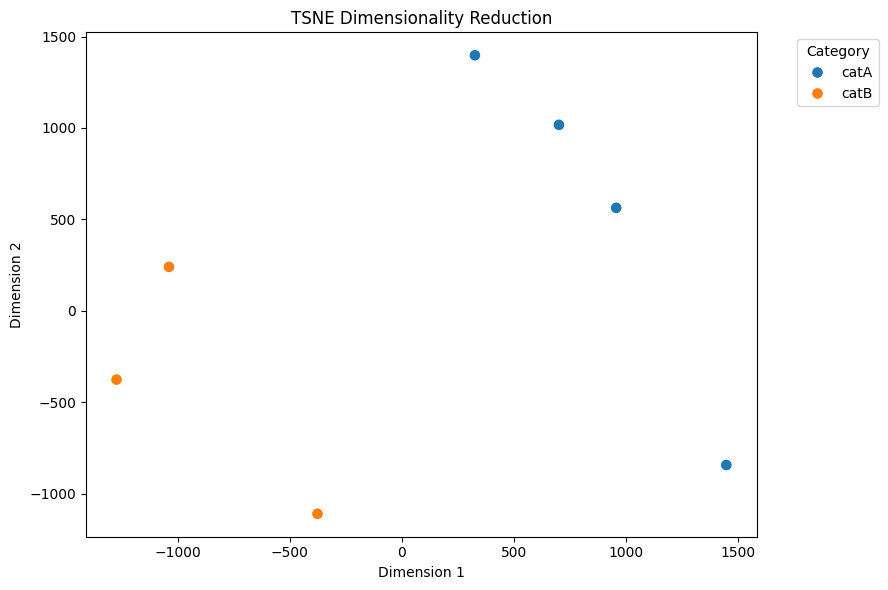

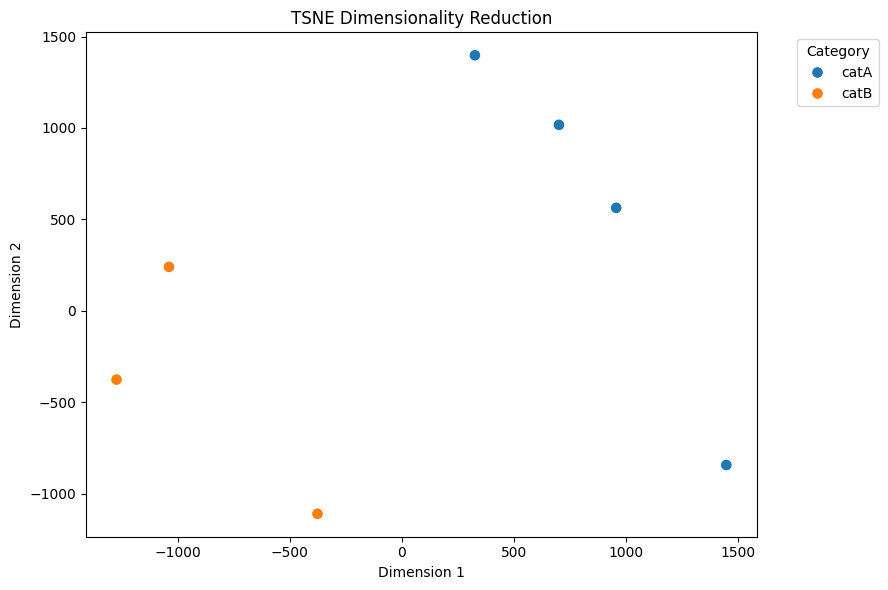

In [4]:
import sys
import importlib.util
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist, pdist
from agent_pipeline.session_state import SessionState


def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module


# 1. Session dengan data fixture
session = SessionState()
session.dataframe = pd.read_csv("agent_dev/sample_fixture.csv").rename(
    columns={"label": "category_name"}
)

# 2. Bangun DTM dulu (reduce_dimensions_tool butuh session.feature_matrix)
dtm_module = load_module("my_dtm_module", "agent_dev_workspace/tools_dtm.py")
dtm_tools = {t.name: t for t in dtm_module.make_tools(session)}
dtm_tools["build_dtm_tool"].invoke({})

# 3. Load tool reduksi
reduction_module = load_module(
    "my_reduction_module", "agent_dev_workspace/tools_reduction.py"
)
reduction_tools = reduction_module.make_tools(session)

# 4. Test t-SNE berbasis properti
tsne_result = reduction_tools[0].invoke(
    {"method": "tsne", "perplexity": 2, "random_state": 42}
)
c = np.array(tsne_result["coordinates"])

assert c.shape == (8, 2) and np.isfinite(c).all()

c2 = np.array(reduction_tools[0].invoke(
    {"method": "tsne", "perplexity": 2, "random_state": 42})["coordinates"])
assert np.allclose(c, c2, atol=1e-5)          # reproducible

assert np.allclose(c[5], c[6], atol=1e-3)     # dokumen duplikat -> titik sama

A, B = c[:3], c[3:7]
within = (pdist(A).mean() + pdist(B).mean()) / 2
between = cdist(A, B).mean()
assert within < between                        # catA dekat, jauh dari catB

assert session.pending_figure is not None
print("PASS: t-SNE properties")
print("within:", round(within), "| between:", round(between))

## 2. Submitting your work

Your session is logged turn by turn to
`session_logs/agent_dev_session.jsonl.enc`, encrypted as it's written.
You can't read your own log back. Your built tools live in
`agent_dev_workspace/`. **Both need to be in your pushed fork.**

**Important: both of those folders are gitignored by default**, so
they can hold your own local test runs without cluttering this shared
repo. That means a plain `git add .` will silently skip them, not
push an empty-looking submission on purpose, just because they're
never staged in the first place. Before your final commit, force-add
them explicitly:
```
git add -f agent_dev_workspace session_logs
git commit -m "agent-dev submission"
git push
```
Run `git status` afterward and confirm both show as staged/committed,
not just `git add .` on its own.

In [ ]:
import os

log_path = "session_logs/agent_dev_session.jsonl.enc"
if os.path.exists(log_path):
    print(f"Log file present: {log_path} ({os.path.getsize(log_path)} bytes)")
else:
    print("No log yet. Send at least one message in the chat above first.")